# Home Credit Default Risk: first data check

The aim of this project is to predict which applicants may experience payment difficulties when applying for a loan. Using applicant information, such as income, credit amount, age, education, and family situation, the model will estimate the likelihood of payment difficulties.

This is important for lenders because better predictions can support credit-risk assessment and help them make more informed lending decisions. However, these decisions should not rely on prediction accuracy alone. Understanding why a model makes a prediction is also important for transparency, trust, and fairness.

#### Purpose

The purpose of this initial notebook is to understand the dataset before developing the machine learning pipeline. I will check the data size, default rate, missing values, available tables and join keys, and sensitive features such as gender and age. I will also train a simple baseline model to establish a starting point for evaluating model performance.

#### Scope

This notebook focuses on initial data exploration and a simple baseline model. It is an early stage of the project, not the final machine learning pipeline or final model. Later stages will compare models, examine their explanations using SHAP, and investigate fairness across applicant groups.


##### Refrences Dataset: https://www.kaggle.com/competitions/home-credit-default-risk/data

## 1. Importing Libraries

- By first importing all python libraries, and then loading the data set

In [47]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, brier_score_loss, precision_score, recall_score,
    f1_score, accuracy_score, confusion_matrix, classification_report
)

DATA_DIR = Path.home() / "Desktop" / "home_credit_default_risk"
RANDOM_STATE = 42

## 2. Load and validate the dataset

In [48]:
df = pd.read_csv(DATA_DIR / "application_train.csv")
n_rows, n_cols = df.shape
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Data Exploration

These basic exploratory steps included:

- Shape
- Datatypes
- Describes
- Target variable Distribution
- Default rate
- Duplicate Rows
- Basleine Scores
- Missing values


### 3a. Column Names and Data Types
I did a basic exploration of the datatypes and some basic statistics of the dataset

In [49]:
print('Shape:', df.shape)
df.dtypes

Shape: (307511, 122)


SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE             object
CODE_GENDER                    object
FLAG_OWN_CAR                   object
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

### 3b. Basic Statistics
The .describe() function provides descriptive statistics of all the numeric columns in the dataset. This is very helpful in terms of count, mean, min, and max values

In [50]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.52,102790.18,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.08,0.27,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.42,0.72,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.92,237123.15,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599026.00,402490.78,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.01,0.11,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.03,0.20,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.27,0.92,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.27,0.79,0.0,0.0,0.0,0.0,261.0


### 3c. Target variable Distribution

- TARGET = 1: Applications where applicants experienced payment difficulties.
- TARGET = 0: Applications where applicants had no recorded payment difficulties.

In [51]:
print("Target counts:")
print(df["TARGET"].value_counts())

Target counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64


### 3d. Default rate

Calculates the percentage of applicants who experienced payment difficulties

In [52]:
print("Default rate:", round(df["TARGET"].mean() * 100, 2), "%")

Default rate: 8.07 %


### 3e. Duplicate Rows
Counts the number of completely duplicated rows in the dataset

In [53]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### 3f. Basleine Scores

Calculates a simple reference Brier score and reports a baseline ROC-AUC of 0.500. These scores provide a benchmark for comparing the performance of machine learning models

In [54]:
default_rate = df["TARGET"].mean()
naive_brier = default_rate * (1 - default_rate)
print("Naive baseline ROC-AUC: 0.500")
print(f"Naive baseline Brier score: {naive_brier:.4f}")

Naive baseline ROC-AUC: 0.500
Naive baseline Brier score: 0.0742


### 3g. Missing values

- Then, I checked which columns have missing values and identified those with more than 50% missing data.
- I also displayed the 15 columns with the highest percentage of missing values to identify potential data quality issues before model training.

In [55]:
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
print("Columns with any missing value:", df.isna().any().sum(), "of", df.shape[1])
print("Columns with more than 50% missing:", (missing_percent > 50).sum())
print("\nTop 15 columns with missing values:")
print(missing_percent.head(15).rename("Missing %").to_frame())

Columns with any missing value: 67 of 122
Columns with more than 50% missing: 41

Top 15 columns with missing values:
                          Missing %
COMMONAREA_MEDI           69.872297
COMMONAREA_AVG            69.872297
COMMONAREA_MODE           69.872297
NONLIVINGAPARTMENTS_MODE  69.432963
NONLIVINGAPARTMENTS_AVG   69.432963
NONLIVINGAPARTMENTS_MEDI  69.432963
FONDKAPREMONT_MODE        68.386172
LIVINGAPARTMENTS_MODE     68.354953
LIVINGAPARTMENTS_AVG      68.354953
LIVINGAPARTMENTS_MEDI     68.354953
FLOORSMIN_AVG             67.848630
FLOORSMIN_MODE            67.848630
FLOORSMIN_MEDI            67.848630
YEARS_BUILD_MEDI          66.497784
YEARS_BUILD_MODE          66.497784


## 4. Feature Selection
- I selected a small set of features that provide useful information about applicants, such as their income, credit amount, age, education, and family situation. I kept `TARGET` separate because it is the outcome the model needs to predict.


In [56]:
candidate_features = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY",
    "AMT_GOODS_PRICE", "DAYS_BIRTH", "DAYS_EMPLOYED",
    "CNT_FAM_MEMBERS", "CNT_CHILDREN",
    "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"
]
features = [c for c in candidate_features if c in df.columns]

# Separate features and target
X = df[features].copy()
y = df["TARGET"].astype(int)

print("Number of features selected:", len(features))
print("Features used:", features)

Number of features selected: 16
Features used: ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS', 'CNT_CHILDREN', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']


## 5. Split into training and validation data


I split the data into 80% for training and 20% for validation. The training data is used to train the model, while the validation data helps me check its performance and compare different models. 
- I will keep a separate test set for the final evaluation. This is an initial random split, so it does not show how well the model will perform on future applications.




In [57]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

Training rows: 246008
Validation rows: 61503


## 6. Prepare numbers and categories

I prepare the data before training the model. 
- `For numerical columns:` I fill missing values with the median and scale the values. 
- `For categorical columns:` I fill in missing values and convert categories into numbers so the model can use them.

In [58]:
number_columns = X_train.select_dtypes(include=["number"]).columns.tolist()
category_columns = [c for c in X_train.columns if c not in number_columns]
number_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
category_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])
prepare_data = ColumnTransformer([
    ("numbers", number_steps, number_columns),
    ("categories", category_steps, category_columns)
])
print("Numeric columns:", len(number_columns))
print("Category columns:", len(category_columns))

Numeric columns: 11
Category columns: 5


## 7. Train two models

I trained two models:

- A simple baseline model for comparison and a Logistic Regression model to learn patterns in the applicant data. After training, I will compare their results to see which model performs better.

In [59]:
baseline = Pipeline([
    ("prepare", prepare_data),
    ("model", DummyClassifier(strategy="prior"))
])
logistic = Pipeline([
    ("prepare", prepare_data),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
baseline.fit(X_train, y_train)
logistic.fit(X_train, y_train)
print("Both models trained.")

Both models trained.


## 8. Compare the models

I compared the baseline model with Logistic Regression using validation data to see how well each predicts payment difficulties. This helps me understand whether Logistic Regression performs better than the simple baseline model.

In [60]:
def evaluate_model(name, model):
    probability = model.predict_proba(X_val)[:, 1]
    prediction = (probability >= 0.5).astype(int)  # Example threshold, not a final lending rule
    return {
        "Model": name,
        "ROC-AUC (higher is better)": roc_auc_score(y_val, probability),
        "Brier score (lower is better)": brier_score_loss(y_val, probability),
        "Precision": precision_score(y_val, prediction, zero_division=0),
        "Recall": recall_score(y_val, prediction, zero_division=0),
        "F1-score": f1_score(y_val, prediction, zero_division=0)
    }
results = pd.DataFrame([
    evaluate_model("Dummy baseline", baseline),
    evaluate_model("Logistic Regression", logistic)
])
display(results.round(4))

,Model,ROC-AUC (higher is better),Brier score (lower is better),Precision,Recall,F1-score
0,Dummy baseline,0.5000,0.0742,0.0000,0.0000,0.0000
1,Logistic Regression,0.7365,0.0691,0.5658,0.0087,0.0171


- `Dummy baseline:` ROC-AUC is 0.500, with a Brier score of 0.0742.
- `Logistic Regression:` Achieves a higher ROC-AUC of 0.7365 and a lower Brier score of 0.0691, showing better overall performance.
- `Precision:` 56.6% of applicants predicted to experience payment difficulties actually did.
- `Recall:` Only 0.87% of actual cases were identified at the 0.5 threshold.
- `F1-score:` 0.0171, reflecting the very low recall.

## 9.Plot ROC-AUC results

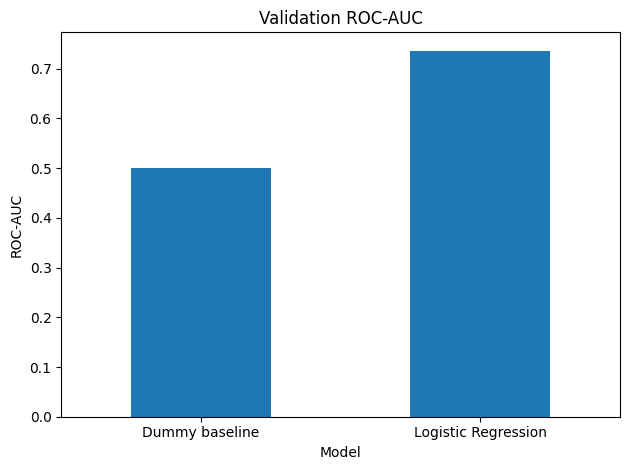

In [61]:
results.set_index("Model")[["ROC-AUC (higher is better)"]].plot(kind="bar", legend=False)
plt.title("Validation ROC-AUC")
plt.ylabel("ROC-AUC")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

It shows that Logistic Regression achieved a higher ROC-AUC score (0.7365) than the Dummy baseline (0.5000). This means Logistic Regression is better at distinguishing between applicants with and without payment difficulties.

## 9. Fairness preview (first look only)
This checks error rates by gender and age group. It is an exploratory analysis, not proof that a model is fair or unfair. Sensitive attributes below are used for auditing, not as model inputs.

In [62]:
probability = logistic.predict_proba(X_val)[:, 1]
prediction = (probability >= 0.5).astype(int)
audit = pd.DataFrame({"actual": y_val, "predicted": prediction}, index=X_val.index)
if "CODE_GENDER" in df.columns:
    audit["gender"] = df.loc[X_val.index, "CODE_GENDER"]
if "DAYS_BIRTH" in df.columns:
    age = -df.loc[X_val.index, "DAYS_BIRTH"] / 365.25
    audit["age_group"] = pd.cut(age, bins=[0, 25, 35, 45, 55, 65, 120],
                                labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])
def error_rates(group):
    actual = group["actual"].to_numpy()
    predicted = group["predicted"].to_numpy()
    fp = ((actual == 0) & (predicted == 1)).sum()
    fn = ((actual == 1) & (predicted == 0)).sum()
    tn = ((actual == 0) & (predicted == 0)).sum()
    tp = ((actual == 1) & (predicted == 1)).sum()
    return pd.Series({
        "group size": len(group),
        "false positive rate": fp / (fp + tn) if fp + tn else np.nan,
        "false negative rate": fn / (fn + tp) if fn + tp else np.nan
    })
for column in ["gender", "age_group"]:
    if column in audit.columns:
        print("Error rates by", column)
        display(audit.groupby(column, observed=False).apply(error_rates).round(3))

Error rates by gender


/var/folders/jp/vwd9v8g146b4r10y6bbxlqjc0000gn/T/ipykernel_41814/1062594259.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(audit.groupby(column, observed=False).apply(error_rates).round(3))


,group size,false positive rate,false negative rate
gender,,,
F,40561.0,0.000,0.993
M,20940.0,0.001,0.989
XNA,2.0,0.000,NaN


Error rates by age_group


/var/folders/jp/vwd9v8g146b4r10y6bbxlqjc0000gn/T/ipykernel_41814/1062594259.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(audit.groupby(column, observed=False).apply(error_rates).round(3))


,group size,false positive rate,false negative rate
age_group,,,
18-24,2392.0,0.006,0.971
25-34,14368.0,0.001,0.985
35-44,16889.0,0.000,0.994
45-54,14039.0,0.000,0.997
55-64,12165.0,0.000,0.999
65+,1650.0,0.000,1.000


## 10. Save the model for comparison
- Saving the model is useful because I can reuse it later without having to train it again.

In [63]:
output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)
results.to_csv(output_folder / "model_comparison.csv", index=False)
print("Saved: outputs/model_comparison.csv")

Saved: outputs/model_comparison.csv


### Save the trained Logistic Regression model

In [64]:
import joblib
from pathlib import Path

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

joblib.dump(logistic, output_folder / "logistic_model.pkl")

print("Logistic Regression model saved.")

Logistic Regression model saved.


### 11. Create a project structure